# IC Macro-Models and Hierarchical Subcircuits

This notebook demonstrates two practical integration patterns using CirKreety-native parsing and analysis:

- A **555-style timing macro block** made from an RC timing network and hysteretic voltage-controlled switch primitives.
- A **nested educational op-amp macro-model** made from controlled sources and resistances.

Neither example is a manufacturer-qualified NE555, LM358, or LM741 model. The point is to demonstrate reusable IC-like subcircuits, numerical analysis, and explicit model boundaries.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from examples.notebook_support import run_example, ac_response, node_voltage, transient_trace, measure_signal


## 1. 555-style timer: RC timing and output switching

The subcircuit is reusable as `XU1 VCC TIMING OUT TIMER555`. It contains an output pull-up and two hysteretic switch elements. The timing capacitor charges through an external resistor and discharges through the switch path. This is a simplified functional abstraction, not the internal transistor topology of a real timer IC.

In [2]:
timer = run_example("timer_555_style_macro")
print(timer.summary())
t, vtiming = transient_trace(timer, node_name="timing")
_, vtimer_out = transient_trace(timer, node_name="out")
timer_metrics = measure_signal(t, vtimer_out, name="timer output")
print(f"Timing capacitor min/max : {vtiming.min():.3f} / {vtiming.max():.3f} V")
print(f"Output logic levels      : {vtimer_out.min():.3f} / {vtimer_out.max():.3f} V")
print(f"Output peak-to-peak      : {timer_metrics.peak_to_peak:.3f} V")
# Estimate oscillator frequency from successive rising threshold crossings.
rising = np.where((vtimer_out[:-1] < 2.5) & (vtimer_out[1:] >= 2.5))[0]
if len(rising) >= 2:
    periods = np.diff(t[rising])
    f_timer = float(1.0 / np.mean(periods))
    print(f"Estimated output frequency: {f_timer:.2f} Hz")
else:
    f_timer = None
    print("Not enough rising edges in this record to estimate frequency.")


{'title': '555-style timer macro block (hysteretic switch abstraction)', 'status': 'success', 'validation_status': 'success', 'kcl_check': 'passed', 'backend': 'nonlinear_analog', 'analysis_status': {'dc_operating_point': 'success', 'dc_sweep': 'success', 'ac_sweep': 'success', 'transient': 'success', 'frequency_analysis': 'not_applicable', 'transfer_function': 'not_applicable', 'state_space': 'not_applicable'}, 'component_count': 6, 'node_count': 3, 'warnings': 0, 'errors': 0}
Timing capacitor min/max : 2.401 / 3.759 V
Output logic levels      : 0.050 / 4.950 V
Output peak-to-peak      : 4.901 V
Estimated output frequency: 274.18 Hz


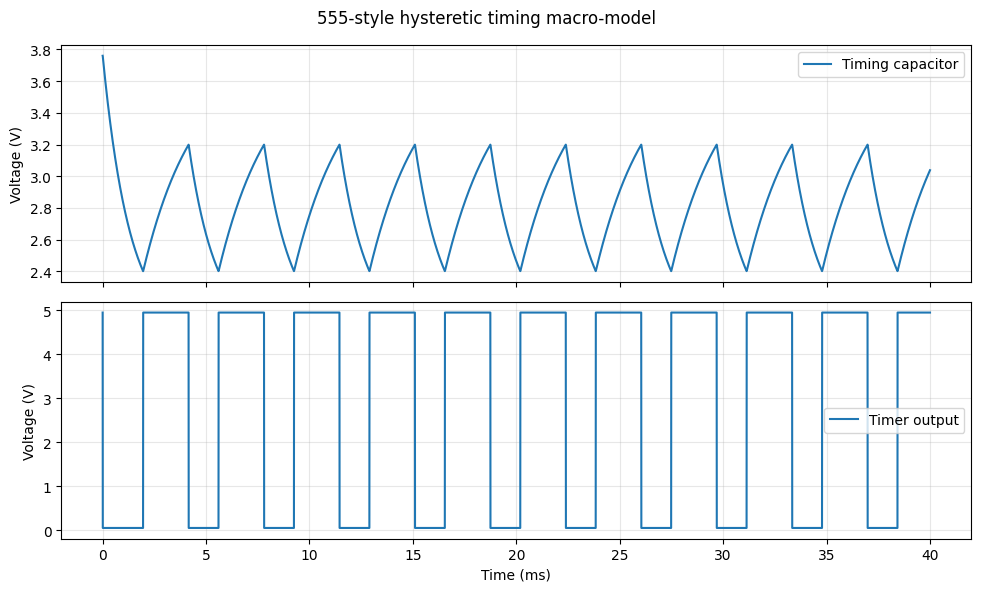

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
axes[0].plot(t * 1e3, vtiming, label="Timing capacitor")
axes[0].set_ylabel("Voltage (V)"); axes[0].legend(); axes[0].grid(True, alpha=0.3)
axes[1].plot(t * 1e3, vtimer_out, label="Timer output")
axes[1].set(xlabel="Time (ms)", ylabel="Voltage (V)"); axes[1].legend(); axes[1].grid(True, alpha=0.3)
fig.suptitle("555-style hysteretic timing macro-model")
fig.tight_layout(); plt.show()


## 2. Nested op-amp macro-model

The outer `OPAMP` block instantiates `OPAMP_CORE`. The core uses a controlled voltage source with finite output resistance. The test circuit uses a non-inverting feedback network.

In [4]:
opamp = run_example("opamp_subcircuit")
print(opamp.summary())
print("Expanded hierarchy records:")
for item in opamp.circuit_ir.hierarchy:
    print(item)
print("Expanded component references:", [c["reference"] for c in opamp.circuit_ir.components])


{'title': 'Nested educational op-amp macro-model example', 'status': 'success', 'validation_status': 'success', 'kcl_check': 'passed', 'backend': 'sparse_mna_dc', 'analysis_status': {'dc_operating_point': 'success', 'dc_sweep': 'success', 'ac_sweep': 'success', 'transient': 'not_applicable', 'frequency_analysis': 'success', 'transfer_function': 'success', 'state_space': 'success'}, 'component_count': 8, 'node_count': 6, 'warnings': 0, 'errors': 0}
Expanded hierarchy records:
{'instance': 'XU1_XCORE', 'subcircuit': 'OPAMP_CORE', 'pin_mapping': {'INP': 'inp', 'INM': 'inm', 'VCC': 'vcc', 'VEE': '0', 'OUT': 'XU1__NDRV'}, 'generated_components': ['E_XU1_XCORE_GAIN', 'R_XU1_XCORE_OUT'], 'depth': 2}
{'instance': 'XU1', 'subcircuit': 'OPAMP', 'pin_mapping': {'INP': 'inp', 'INM': 'inm', 'VCC': 'vcc', 'VEE': '0', 'OUT': 'out'}, 'generated_components': ['R_XU1_LOADISO'], 'depth': 1}
Expanded component references: ['VCC', 'VIN', 'RFB', 'RG', 'RL', 'E_XU1_XCORE_GAIN', 'R_XU1_XCORE_OUT', 'R_XU1_LOAD

## 3. DC operating point and closed-loop AC gain

The nominal non-inverting gain is \(1+R_f/R_g=11\). The implemented open-loop gain is finite, so the computed response is expected to be close to, not mathematically identical to, the ideal ratio.

In [5]:
vout_dc = node_voltage(opamp, "out")
frequency, gain_db, phase_deg = ac_response(opamp)
probe = int(np.argmin(np.abs(frequency - 1_000.0)))
measured_gain = 10 ** (gain_db[probe] / 20.0)
print(f"DC output voltage         : {vout_dc:.6f} V")
print(f"Ideal closed-loop gain    : {1 + 10_000/1_000:.3f} V/V")
print(f"AC gain near 1 kHz        : {measured_gain:.4f} V/V")
print(f"AC gain near 1 kHz        : {gain_db[probe]:.3f} dB")


DC output voltage         : 10.987683 V
Ideal closed-loop gain    : 11.000 V/V
AC gain near 1 kHz        : 10.9877 V/V
AC gain near 1 kHz        : 20.818 dB


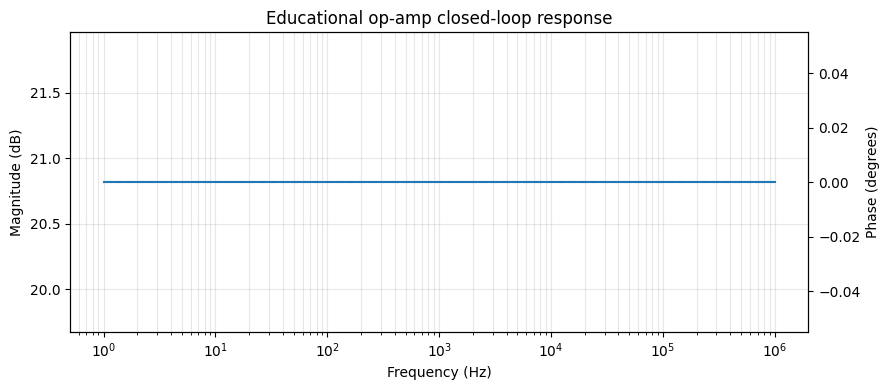

In [6]:
fig, ax1 = plt.subplots(figsize=(9, 4))
ax1.semilogx(frequency, gain_db, label="Magnitude")
ax1.set(title="Educational op-amp closed-loop response", xlabel="Frequency (Hz)", ylabel="Magnitude (dB)")
ax1.grid(True, which="both", alpha=0.3)
if phase_deg is not None:
    ax2 = ax1.twinx(); ax2.semilogx(frequency, phase_deg, linestyle="--", alpha=0.7, label="Phase")
    ax2.set_ylabel("Phase (degrees)")
fig.tight_layout(); plt.show()


## 4. Integration pattern and cautions

- Keep reusable chip blocks as subcircuits with explicit pin order and parameters.
- Preserve hierarchy and source metadata in `CircuitIR` for downstream tools.
- Add new model parameters only when the parser, solver adapter, and reference tests all support them.
- Attach board/project checks through `ReviewPlugin` rather than embedding product-specific design rules inside the numerical solver.

The timer example is a hysteretic switch oscillator; the op-amp example is a controlled-source macro-model. Neither should be substituted for a selected manufacturer's validated model when making design decisions.

In [7]:
from examples.plugins.resistor_power_rating import ResistorPowerRatingPlugin
from circhecker import CircuitReviewer

plugin = ResistorPowerRatingPlugin({"RFB": 0.125, "RG": 0.125})
plugin_review = CircuitReviewer(review_plugins=[plugin]).process_file(
    "examples/circuits/ic/idealized_opamp_subcircuit.cir",
    analyses=["dc_operating_point"], save_json=False, plot=False,
)
print(plugin_review.plugin_results)


{'resistor_power_rating_dc': {'status': 'success', 'data': {'scope': 'DC operating-point resistor dissipation only; transient pulse, thermal, PCB and derating checks are not assessed', 'safety_fraction': 1.0, 'checks': [{'reference': 'RFB', 'status': 'not_evaluated', 'rating_W': 0.125, 'reason': 'No DC operating-point power metric is available.'}, {'reference': 'RG', 'status': 'not_evaluated', 'rating_W': 0.125, 'reason': 'No DC operating-point power metric is available.'}]}}}
